# How to: Empirical Reliability Function

This tutorial demonstrates how to use pandaICT's `empirical_reliability_function` to compute and visualize the reliability function R(t) = P(T > t), which represents the probability that a system survives longer than time t.

## What is the Reliability Function?

The reliability function R(t) answers a fundamental question:

> **"What is the probability that the system will still be operational after time t?"**

Mathematically:
$$R(t) = P(T > t)$$

where T is the random variable representing the system's lifetime.

### Key Properties

| Property | Description |
|----------|-------------|
| R(0) = 1 | System starts operational |
| R(∞) = 0 | System eventually fails |
| Monotonically decreasing | Reliability always decreases with time |

### Why is R(t) Important?

The reliability function is essential for:

- **Warranty planning**: "What percentage will fail within 1 year?"
- **Maintenance scheduling**: "When should preventive maintenance occur?"
- **Spare parts inventory**: "How many replacements needed in 5 years?"
- **Lifecycle cost analysis**: "Expected lifetime cost of the system"

In [12]:
import pandaict as pi
from pandaict.reliability.reliability import (
    empirical_reliability_function,
    estimate_mtbf_mttr_for_conn
)
import numpy as np
import matplotlib.pyplot as plt

from demo_networks import (
    single_component_net,
    series_two_component_net,
    parallel_redundant_net
)

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 12

---

## Theoretical Background

### For Exponential Time-to-Failure

When component failure times follow an exponential distribution:
```{math}
R(t) = e^{-\lambda t} = e^{-t/MTBF}
```
where λ = 1/MTBF is the failure rate.

### Series vs Parallel Systems

| System | Reliability Function | Distribution |
|--------|-------------------|-------------|
| Single component | $R(t) = e^{-t/MTBF}$ | Exponential |
| n components in series | $R(t) = e^{-n \cdot t/MTBF}$ | Exponential |
| 2 components in parallel | $R(t) = 1 - (1 - e^{-t/MTBF})^2$ | **Non-exponential** |

---

## Example 1: Single Component (Pure Exponential)

Let's start with the simplest case: a single fail-able component. The reliability function should be a pure exponential.

**Network:**
```
   [Alice] -- NodeA -- [Bob]
```

NodeA has MTBF = 8760 hours (1 year) and is **non-repairable**.

**Expected**: R(t) = exp(-t/8760)

In [13]:
# Create single component network
net, appA, appB, node = single_component_net()

# Create connection
conn = pi.create_ict_connection(net, name='Conn', from_app=appA, to_app=appB, protocol='TCP')

print("Network: Single Component (Non-Repairable)")
print("-" * 40)
print(f"NodeA: MTBF = 8760 hours (1 year)")
print(f"       MTTR = 0 (non-repairable)")
print("-" * 40)


Network: Single Component (Non-Repairable)
----------------------------------------
NodeA: MTBF = 8760 hours (1 year)
       MTTR = 0 (non-repairable)
----------------------------------------


In [14]:
# Get MTTF for reference
result = estimate_mtbf_mttr_for_conn(net, [conn], N=50000)
mtbf = result['mtbf_h']
print(f"Monte Carlo MTTF: {mtbf:.2f} hours")
print(f"Expected MTTF: 8760 hours")
print(f"Relative error: {abs(mtbf - 8760)/8760*100:.2f}%")

Running 50000 simulations in parallel...
Monte Carlo MTTF: 8765.13 hours
Expected MTTF: 8760 hours
Relative error: 0.06%


Running 100000 simulations in parallel...


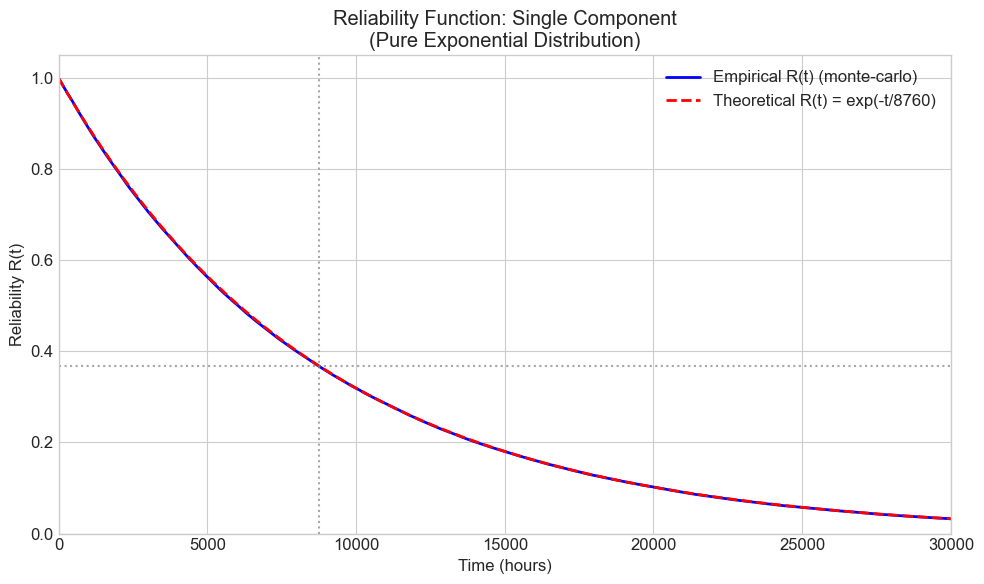


At t = 8760 hours (1 year):
  Empirical R(8760): 0.3678
  Theoretical R(8760): 0.3679


In [15]:
# Compute empirical reliability function
T = np.linspace(0, 30000, 200)  # 0 to 30,000 hours (~3.4 years)

R_empirical = empirical_reliability_function(net, [conn], T, N=100000)

# Theoretical exponential reliability
MTBF = 8760
R_theoretical = np.exp(-T / MTBF)

# Plot
fig, ax = plt.subplots()

ax.plot(T, R_empirical, 'b-', linewidth=2, label='Empirical R(t) (monte-carlo)')
ax.plot(T, R_theoretical, 'r--', linewidth=2, label=f'Theoretical R(t) = exp(-t/{MTBF})')

ax.set_xlabel('Time (hours)')
ax.set_ylabel('Reliability R(t)')
ax.set_title('Reliability Function: Single Component\n(Pure Exponential Distribution)')
ax.legend(loc='upper right')
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 30000)
ax.axhline(y=np.exp(-8760/MTBF), color='gray', linestyle=':', alpha=0.7)
ax.axvline(x=8760, color='gray', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

print(f"\nAt t = 8760 hours (1 year):")
print(f"  Empirical R(8760): {R_empirical[np.argmin(np.abs(T - 8760))]:.4f}")
print(f"  Theoretical R(8760): {np.exp(-1):.4f}")

**Observation**: The empirical reliability function closely matches the theoretical exponential curve!

Notice that after 1 year (8760 hours), reliability drops to about 37%.

---

## Example 2: Two Components in Series (Still Exponential)

Now let's add another fail-able component in series. For non-repairable components in series, the reliability is still exponential!

**Network:**
```
   [Alice] -- NodeA -- NodeB -- [Bob]
```

Both NodeA and NodeB have MTBF = 8760 hours and are **non-repairable**.

**Expected**: R(t) = exp(-2t/8760)

In [16]:
# Create series network
net, appA, appB, nodes = series_two_component_net()
nodeA, nodeB = nodes

conn = pi.create_ict_connection(net, name='Conn', from_app=appA, to_app=appB, protocol='TCP')

print("Network: Two Components in Series (Non-Repairable)")
print("-" * 40)
print(f"NodeA: MTBF = 8760 hours")
print(f"NodeB: MTBF = 8760 hours")
print(f"Both non-repairable (MTTR = 0)")
print("-" * 40)

Network: Two Components in Series (Non-Repairable)
----------------------------------------
NodeA: MTBF = 8760 hours
NodeB: MTBF = 8760 hours
Both non-repairable (MTTR = 0)
----------------------------------------


In [17]:
# Get MTTF
result = estimate_mtbf_mttr_for_conn(net, [conn], N=50000)
mtbf = result['mtbf_h']
print(f"Monte Carlo MTTF: {mtbf:.2f} hours")
print(f"Expected MTTF: 8760/2 = 4380 hours")
print(f"Relative error: {abs(mtbf - 4380)/4380*100:.2f}%")

Running 50000 simulations in parallel...
Monte Carlo MTTF: 4374.12 hours
Expected MTTF: 8760/2 = 4380 hours
Relative error: 0.13%


Running 100000 simulations in parallel...


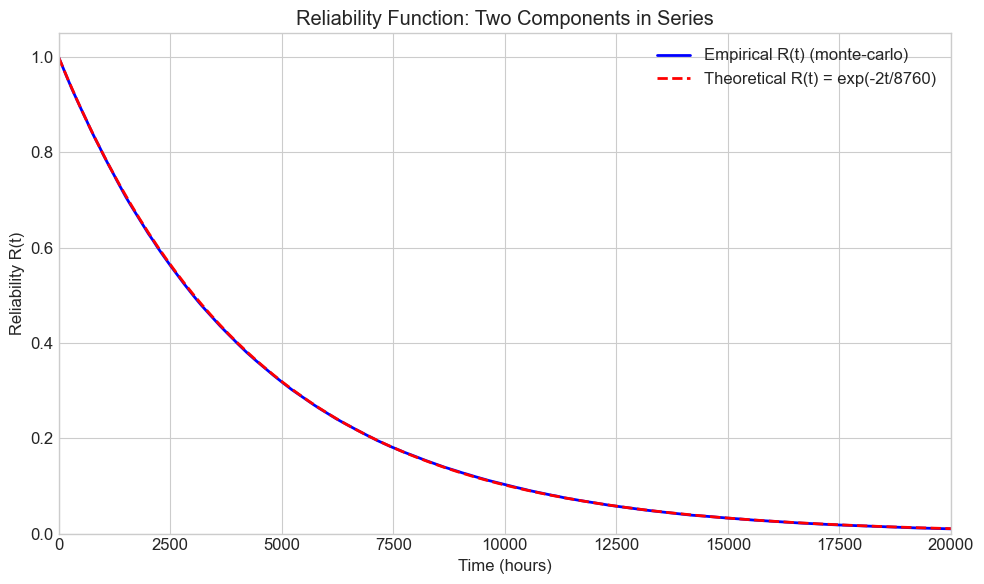


At t = 4380 hours (half the single-component MTBF):
  Empirical R(4380): 0.3631
  Theoretical R(4380): 0.3679


In [18]:
# Compute empirical reliability function
T = np.linspace(0, 20000, 200)

R_empirical = empirical_reliability_function(net, [conn], T, N=100000)

# Theoretical: still exponential with effective rate = 2/MTBF
MTBF = 8760
R_theoretical = np.exp(-2 * T / MTBF)

# Plot
fig, ax = plt.subplots()

ax.plot(T, R_empirical, 'b-', linewidth=2, label='Empirical R(t) (monte-carlo)')
ax.plot(T, R_theoretical, 'r--', linewidth=2, label=f'Theoretical R(t) = exp(-2t/{MTBF})')

ax.set_xlabel('Time (hours)')
ax.set_ylabel('Reliability R(t)')
ax.set_title('Reliability Function: Two Components in Series')
ax.legend(loc='upper right')
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 20000)

plt.tight_layout()
plt.show()

print(f"\nAt t = 4380 hours (half the single-component MTBF):")
print(f"  Empirical R(4380): {R_empirical[np.argmin(np.abs(T - 4380))]:.4f}")
print(f"  Theoretical R(4380): {np.exp(-1):.4f}")

**Observation**: Even with two components in series, the reliability function remains exponential!

The failure rate doubles (2/MTBF instead of 1/MTBF), so reliability drops faster, but it's still a pure exponential.

After half the time (4380 hours), reliability is already at 37%.

---

## Example 3: Parallel Components (Non-Exponential!)

Now here's where it gets interesting! With parallel redundancy, the reliability function is **NOT** purely exponential.

**Network:**
```
              +-- NodeA --+
    [Alice] --+            +-- [Bob]
              +-- NodeB --+
```

NodeA and NodeB are in **parallel** - either one can provide connectivity. The system only fails if BOTH components fail.

**Expected**: 
$$R(t) = 1 - (1 - e^{-t/MTBF})^2 = 2e^{-t/MTBF} - e^{-2t/MTBF}$$

This is a quadratic in exp(-t/MTBF), NOT a pure exponential!

In [19]:
# Create parallel network
net, appA, appB, nodes = parallel_redundant_net()
nodeA, nodeB = nodes

conn = pi.create_ict_connection(net, name='Conn', from_app=appA, to_app=appB, protocol='TCP')

print("Network: Two Components in PARALLEL (Redundancy)")
print("-" * 50)
print("Either NodeA OR NodeB can provide connectivity.")
print("System ONLY fails if BOTH fail.")
print("-" * 50)
print(f"NodeA: MTBF = 8760 hours (non-repairable)")
print(f"NodeB: MTBF = 8760 hours (non-repairable)")

Network: Two Components in PARALLEL (Redundancy)
--------------------------------------------------
Either NodeA OR NodeB can provide connectivity.
System ONLY fails if BOTH fail.
--------------------------------------------------
NodeA: MTBF = 8760 hours (non-repairable)
NodeB: MTBF = 8760 hours (non-repairable)


In [20]:
# Get MTTF
result = estimate_mtbf_mttr_for_conn(net, [conn], N=50000)
mtbf = result['mtbf_h']
print(f"\nMonte Carlo MTTF: {mtbf:.2f} hours")
print("Expected MTTF: 1.5 x MTBF = 13140 hours (for 2 identical parallel components)")

Running 50000 simulations in parallel...

Monte Carlo MTTF: 13110.10 hours
Expected MTTF: 1.5 x MTBF = 13140 hours (for 2 identical parallel components)


Running 100000 simulations in parallel...


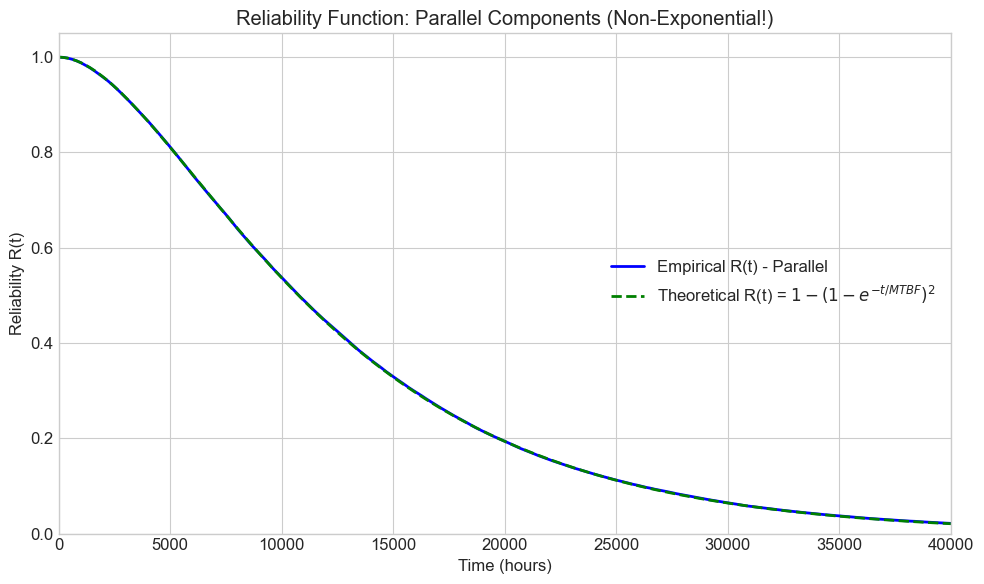


KEY INSIGHT: The parallel curve is HIGHER than exponential
for small to medium times due to redundancy protection!


In [21]:
# Compute empirical reliability function
T = np.linspace(0, 40000, 200)

R_empirical = empirical_reliability_function(net, [conn], T, N=100000)

# Theoretical for parallel (non-exponential!)
MTBF = 8760
p_fail = 1 - np.exp(-T / MTBF)  # P(single component fails by time t)
p_both_fail = p_fail ** 2  # P(both components fail by time t)
R_theoretical_parallel = 1 - p_both_fail

# Plot
fig, ax = plt.subplots()

ax.plot(T, R_empirical, 'b-', linewidth=2, label='Empirical R(t) - Parallel')
ax.plot(T, R_theoretical_parallel, 'g--', linewidth=2, 
        label=r'Theoretical R(t) = $1 - (1 - e^{-t/MTBF})^2$')

ax.set_xlabel('Time (hours)')
ax.set_ylabel('Reliability R(t)')
ax.set_title('Reliability Function: Parallel Components (Non-Exponential!)')
ax.legend(loc='right')
ax.set_ylim(0, 1.05)
ax.set_xlim(0, 40000)

plt.tight_layout()
plt.show()

print("\n" + "=" * 50)
print("KEY INSIGHT: The parallel curve is HIGHER than exponential")
print("for small to medium times due to redundancy protection!")
print("=" * 50)

**Key Observations**:

1. **Non-Exponential**: The reliability function for parallel components is NOT a pure exponential

2. **Higher Reliability**: At any given time, parallel redundancy gives higher reliability than a single component

3. **Formula**: R(t) = 1 - (1 - exp(-t/MTBF))² = 2exp(-t/MTBF) - exp(-2t/MTBF)

4. **Long-term behavior**: Both curves eventually converge to zero, but the parallel system takes longer

---

## Comparing All Three: Exponential vs Non-Exponential

Let's put all three cases together to see the difference clearly.

Running 100000 simulations in parallel...
Running 100000 simulations in parallel...
Running 100000 simulations in parallel...


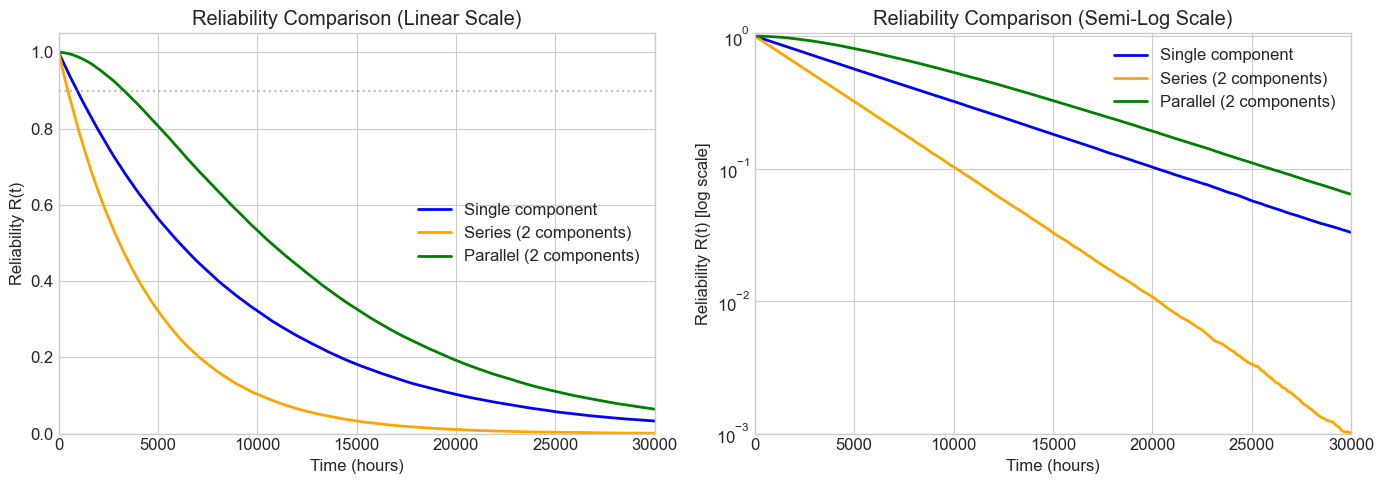

In [22]:
# Recompute all three cases
T = np.linspace(0, 30000, 200)

# Single component
net1, appA1, appB1, _ = single_component_net()
conn1 = pi.create_ict_connection(net1, name='Conn', from_app=appA1, to_app=appB1, protocol='TCP')
R1 = empirical_reliability_function(net1, [conn1], T, N=100000)

# Series
net2, appA2, appB2, _ = series_two_component_net()
conn2 = pi.create_ict_connection(net2, name='Conn', from_app=appA2, to_app=appB2, protocol='TCP')
R2 = empirical_reliability_function(net2, [conn2], T, N=100000)

# Parallel
net3, appA3, appB3, _ = parallel_redundant_net()
conn3 = pi.create_ict_connection(net3, name='Conn', from_app=appA3, to_app=appB3, protocol='TCP')
R3 = empirical_reliability_function(net3, [conn3], T, N=100000)

# Plot comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Linear scale
ax1.plot(T, R1, 'b-', linewidth=2, label='Single component')
ax1.plot(T, R2, 'orange', linewidth=2, label='Series (2 components)')
ax1.plot(T, R3, 'g-', linewidth=2, label='Parallel (2 components)')

ax1.set_xlabel('Time (hours)')
ax1.set_ylabel('Reliability R(t)')
ax1.set_title('Reliability Comparison (Linear Scale)')
ax1.legend()
ax1.set_ylim(0, 1.05)
ax1.set_xlim(0, 30000)
ax1.axhline(y=0.9, color='gray', linestyle=':', alpha=0.5)

# Right plot: Semi-log scale
ax2.semilogy(T, R1, 'b-', linewidth=2, label='Single component')
ax2.semilogy(T, R2, 'orange', linewidth=2, label='Series (2 components)')
ax2.semilogy(T, R3, 'g-', linewidth=2, label='Parallel (2 components)')

ax2.set_xlabel('Time (hours)')
ax2.set_ylabel('Reliability R(t) [log scale]')
ax2.set_title('Reliability Comparison (Semi-Log Scale)')
ax2.legend()
ax2.set_ylim(0.001, 1.05)
ax2.set_xlim(0, 30000)

plt.tight_layout()
plt.show()

**Observations from the comparison**:

| System | Shape | Behavior |
|--------|-------|----------|
| **Single component** | Pure exponential | Straight line on semi-log plot |
| **Series** | Pure exponential | Straight line, steeper slope |
| **Parallel** | Non-exponential | Curves upward (convex) - NOT a straight line |

The semi-log plot makes it easy to identify exponential vs non-exponential behavior:
- Exponential distributions appear as straight lines
- Non-exponential distributions show curvature

---

## Summary

### Key Takeaways

1. **R(t) = P(T > t)** represents the probability the system survives longer than time t

2. **Exponential systems** (single component, series):
   - R(t) = exp(-λt)
   - Appears as straight line on semi-log plot
   - Memoryless property

3. **Non-exponential systems** (parallel redundancy):
   - R(t) = 1 - (1 - exp(-λt))^n
   - Curved on semi-log plot (higher than exponential initially)
   - Provides better reliability than exponential prediction

4. **Practical uses**:
   - Warranty period planning
   - Maintenance scheduling
   - Spare parts inventory

### When to Use Each Model

| Scenario | Recommended Model |
|----------|-------------------|
| Single non-repairable component | Exponential |
| Series of non-repairable components | Exponential |
| Components in parallel (redundancy) | Non-exponential |
| Mixed topologies | Empirical from Monte Carlo |